# Baseline vs. Transformer Comparison + Results Write-up - Jackie Perales and Patricia Ji

Milestone 2, Task #6. This notebook puts the TF-IDF baseline and the fine-tuned transformers side by side, **one row per clause category**, so we can see exactly where the transformer beats the baseline and where it doesn't.

1. Rebuilds the TF-IDF baseline from `TF-IDF_Baseline.ipynb` (same features, same model, same settings) to get its per-chunk test predictions
2. Loads the saved test probabilities for RoBERTa and Legal-BERT from `Training_Optimization_Model_Selection.ipynb` (`results/training/15ep/`)
3. Scores all three models on the same 2,898 test chunks with per-category precision, recall and F1
4. Builds **one comparison table** (TF-IDF F1 vs RoBERTa F1 vs Legal-BERT F1, with the change per category)
5. Shows which categories improved, which got worse, and why
6. Saves the table and chart to `results/comparison/` and summarizes the findings for the README

**Why both transformers?** The task says "RoBERTa", but Task #2 trained two models and chose **Legal-BERT** on validation (higher macro AP). We compare both against the baseline and treat Legal-BERT as the final model.

**Fair comparison rules.** All three models are scored on the same test chunks, with the same 0.5 decision threshold, and the same rule from the earlier notebooks: a category with no test positives (Price Restrictions) is excluded from the averages. Nothing here was tuned on the test set.

In [1]:
import json, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import precision_recall_fscore_support

DATA_DIR = '../data/processed'
RESULTS_DIR = '../results/training/15ep'      # saved by Training_Optimization_Model_Selection.ipynb
OUT_DIR = '../results/comparison'
os.makedirs(OUT_DIR, exist_ok=True)

THRESHOLD = 0.5   # same fixed threshold as the baseline and the training notebook; Task #3 tunes this per category

## 1. Load the labeled test chunks and the category list

Same files as every other notebook: one row per chunk, `chunk_text`, and one 0/1 column per category.

In [2]:
train_df = pd.read_parquet(f'{DATA_DIR}/train_chunks_labeled.parquet')
test_df = pd.read_parquet(f'{DATA_DIR}/test_chunks_labeled.parquet')
with open(f'{DATA_DIR}/categories.json') as f:
    CATEGORIES = json.load(f)

y_train = train_df[CATEGORIES].to_numpy()
y_test = test_df[CATEGORIES].to_numpy()

print("Train chunks:", train_df.shape)   # expect (14181, 46)
print("Test chunks: ", test_df.shape)    # expect (2898, 46)
print("Categories:  ", len(CATEGORIES))  # expect 41

Train chunks: (14181, 46)
Test chunks:  (2898, 46)
Categories:   41


## 2. Rebuild the TF-IDF baseline

`TF-IDF_Baseline.ipynb` doesn't save its predictions, so we retrain it here with **exactly the same code**: the word tokenizer from `Tokenization.ipynb`, 1-2 word phrases, `min_df=5`, `sublinear_tf=True`, and one-vs-rest logistic regression with `class_weight='balanced'`, `solver='liblinear'`, `C=1.0`. `liblinear` is deterministic, so this reproduces Jeslyn's numbers (micro F1 0.591, macro F1 0.517). We check that below.

Note the baseline trains on all 408 training contracts, while the transformers trained on 347 (61 were held out for validation). That slightly favors the baseline.

In [3]:
TOKEN_PATTERN = r"\$\s*\d+(?:[.,]\d+)*|\d+(?:[.,]\d+)*|[a-z]+(?:[-'][a-z]+)*"

def tokenize_words(text):
    tokens = re.findall(TOKEN_PATTERN, text.lower())
    cleaned = []
    for token in tokens:
        if token.startswith("$"):
            cleaned.append("<money>")
        elif token[0].isdigit():
            cleaned.append("<num>")
        else:
            cleaned.append(token)
    return cleaned

vectorizer = TfidfVectorizer(tokenizer=tokenize_words, lowercase=False, token_pattern=None,
                             ngram_range=(1, 2), min_df=5, sublinear_tf=True)
X_train = vectorizer.fit_transform(train_df['chunk_text'])
X_test = vectorizer.transform(test_df['chunk_text'])

baseline = OneVsRestClassifier(
    LogisticRegression(class_weight='balanced', solver='liblinear', C=1.0, max_iter=1000))   # n_jobs=1: same result, avoids a joblib read-only error on some machines
baseline.fit(X_train, y_train)

tfidf_probs = baseline.predict_proba(X_test)
print("X_train:", X_train.shape, "| TF-IDF test probabilities:", tfidf_probs.shape)   # expect (14181, 98157) and (2898, 41)

X_train: (14181, 98157) | TF-IDF test probabilities: (2898, 41)


## 3. Load the transformer test predictions

`Training_Optimization_Model_Selection.ipynb` saved one probability per category per test chunk for each model (`test_predictions.parquet`). We check the rows are in the same order as `test_df` before using them.

In [4]:
MODEL_FILES = {'RoBERTa': 'roberta', 'Legal-BERT': 'legal-bert'}
probs = {'TF-IDF': tfidf_probs}

for name, tag in MODEL_FILES.items():
    pred = pd.read_parquet(f'{RESULTS_DIR}/{tag}/test_predictions.parquet')
    assert (pred['title'].to_numpy() == test_df['title'].to_numpy()).all()
    assert (pred['chunk_id'].to_numpy() == test_df['chunk_id'].to_numpy()).all()
    probs[name] = pred[CATEGORIES].to_numpy()
    print(f"{name:10s} predictions: {probs[name].shape}  (rows match test_df)")

with open(f'{RESULTS_DIR}/legal-bert/summary.json') as f:
    legalbert_summary = json.load(f)
print("\nTraining notebook's own Legal-BERT test scores (for a sanity check later):",
      {k: round(v, 3) for k, v in legalbert_summary['test_at_best_epoch'].items() if 'f1' in k})

RoBERTa    predictions: (2898, 41)  (rows match test_df)
Legal-BERT predictions: (2898, 41)  (rows match test_df)

Training notebook's own Legal-BERT test scores (for a sanity check later): {'micro_f1': 0.703, 'macro_f1': 0.569}


## 4. Per-category precision, recall and F1 for every model

Same scoring as the earlier notebooks: predicted = probability >= 0.5, `precision_recall_fscore_support` per category, and recall/F1 set to `NaN` where there are no test positives.

In [5]:
def per_category(y_true, y_prob, threshold=THRESHOLD):
    y_pred = (y_prob >= threshold).astype(int)
    p, r, f, support = precision_recall_fscore_support(y_true, y_pred, average=None, zero_division=0)
    out = pd.DataFrame({'precision': p, 'recall': r, 'f1': f, 'test_support': support}, index=CATEGORIES)
    out.loc[out['test_support'] == 0, ['recall', 'f1']] = np.nan   # can't be measured
    return out

scores = {name: per_category(y_test, pr) for name, pr in probs.items()}

no_test_positives = scores['TF-IDF']['test_support'] == 0
measurable = ~no_test_positives.to_numpy()
print("Excluded from averages (no test positives):", list(scores['TF-IDF'].index[no_test_positives]))

# Overall micro / macro over the 40 measurable categories
rows = []
for name, pr in probs.items():
    y_pred = (pr >= THRESHOLD).astype(int)
    for avg in ['micro', 'macro']:
        p, r, f, _ = precision_recall_fscore_support(y_test[:, measurable], y_pred[:, measurable], average=avg, zero_division=0)
        rows.append({'model': name, 'average': avg, 'precision': p, 'recall': r, 'f1': f})
overall = pd.DataFrame(rows).set_index(['model', 'average'])
overall.round(3)

Excluded from averages (no test positives): ['Price Restrictions']


precision  recall     f1
model      average                          
TF-IDF     micro        0.519   0.686  0.591
           macro        0.511   0.584  0.517
RoBERTa    micro        0.756   0.638  0.692
           macro        0.636   0.485  0.524
Legal-BERT micro        0.774   0.643  0.703
           macro        0.673   0.522  0.569

**Sanity check.** These should match the numbers already in the repo: TF-IDF micro 0.591 / macro 0.517 (`TF-IDF_Baseline.ipynb`), RoBERTa 0.692 / 0.524 and Legal-BERT 0.703 / 0.569 (`results/training/15ep/model_comparison.csv`).

In [6]:
expected = pd.read_csv(f'{RESULTS_DIR}/model_comparison.csv').set_index('model')
checks = {
    'TF-IDF':     (expected.loc['tf-idf baseline', 'test_micro_f1'], expected.loc['tf-idf baseline', 'test_macro_f1']),
    'RoBERTa':    (expected.loc['roberta', 'test_micro_f1'],         expected.loc['roberta', 'test_macro_f1']),
    'Legal-BERT': (expected.loc['legal-bert', 'test_micro_f1'],      expected.loc['legal-bert', 'test_macro_f1']),
}
for name, (micro, macro) in checks.items():
    got_micro, got_macro = overall.loc[(name, 'micro'), 'f1'], overall.loc[(name, 'macro'), 'f1']
    ok = abs(got_micro - micro) < 0.002 and abs(got_macro - macro) < 0.002
    print(f"{name:10s} micro {got_micro:.3f} (expected {micro:.3f})  macro {got_macro:.3f} (expected {macro:.3f})  {'OK' if ok else 'MISMATCH'}")

TF-IDF     micro 0.591 (expected 0.591)  macro 0.517 (expected 0.517)  OK
RoBERTa    micro 0.692 (expected 0.692)  macro 0.524 (expected 0.524)  OK
Legal-BERT micro 0.703 (expected 0.703)  macro 0.569 (expected 0.569)  OK


## 5. The comparison table: one row per category

For each of the 41 categories: how many test chunks truly contain it, the test F1 of each model, and the change from the baseline. `best_model` is the model with the highest F1 for that category. A category "improved" if the final model (Legal-BERT) beats the baseline by more than 0.02 F1, "got worse" if it is more than 0.02 below, and is "about the same" otherwise. The 0.02 margin keeps tiny differences from being over-read; the training notebook estimates about ±0.01 of noise between runs.

In [7]:
MARGIN = 0.02

table = pd.DataFrame({
    'test_support': scores['TF-IDF']['test_support'],
    'train_support': y_train.sum(axis=0),
    'tfidf_f1': scores['TF-IDF']['f1'],
    'roberta_f1': scores['RoBERTa']['f1'],
    'legalbert_f1': scores['Legal-BERT']['f1'],
}, index=CATEGORIES)
table['roberta_change'] = table['roberta_f1'] - table['tfidf_f1']
table['legalbert_change'] = table['legalbert_f1'] - table['tfidf_f1']
table['best_model'] = table[['tfidf_f1', 'roberta_f1', 'legalbert_f1']].fillna(-1).idxmax(axis=1).str.replace('_f1', '').map(
    {'tfidf': 'TF-IDF', 'roberta': 'RoBERTa', 'legalbert': 'Legal-BERT'})
table['result'] = np.select(
    [table['legalbert_change'] > MARGIN, table['legalbert_change'] < -MARGIN],
    ['improved', 'got worse'], default='about the same')
table.loc[no_test_positives, ['best_model', 'result']] = 'not measurable'
table['few_test_examples'] = table['test_support'] < 20   # F1 is noisy here (from TF-IDF_Baseline.ipynb)

table = table.sort_values('legalbert_change', ascending=False)
table.index.name = 'category'
table.to_csv(f'{OUT_DIR}/baseline_vs_transformer_per_category.csv')

pd.set_option('display.max_rows', 50)
pd.set_option('display.width', 160)
table.round(3)

,test_support,train_support,tfidf_f1,roberta_f1,legalbert_f1,roberta_change,legalbert_change,best_model,result,few_test_examples
category,,,,,,,,,,
Non-Disparagement,15,64,0.222,0.000,0.571,-0.222,0.349,Legal-BERT,improved,True
Joint Ip Ownership,15,99,0.556,0.235,0.800,-0.320,0.244,Legal-BERT,improved,True
Non-Transferable License,43,299,0.444,0.684,0.684,0.239,0.240,Legal-BERT,improved,False
Irrevocable Or Perpetual License,31,175,0.506,0.680,0.717,0.174,0.211,Legal-BERT,improved,False
Non-Compete,64,237,0.565,0.608,0.770,0.043,0.205,Legal-BERT,improved,False
Uncapped Liability,23,192,0.525,0.667,0.720,0.142,0.195,Legal-BERT,improved,False
Expiration Date,111,525,0.672,0.874,0.839,0.202,0.168,RoBERTa,improved,False
Liquidated Damages,28,108,0.474,0.429,0.636,-0.045,0.163,Legal-BERT,improved,False
Cap On Liability,122,640,0.671,0.802,0.827,0.130,0.155,Legal-BERT,improved,False


## 6. Which categories improved?

Counting the 40 categories that can be measured. Only the final model (Legal-BERT) counts here; RoBERTa is in the table for reference.

In [8]:
counts = table.loc[~no_test_positives, 'result'].value_counts()
print("Legal-BERT vs TF-IDF baseline, 40 measurable categories:")
for k in ['improved', 'about the same', 'got worse']:
    print(f"  {k:15s} {counts.get(k, 0):2d}")

print("\nRoBERTa vs TF-IDF: improved by > 0.02 in", int((table['roberta_change'] > MARGIN).sum()), "categories,",
      "worse by > 0.02 in", int((table['roberta_change'] < -MARGIN).sum()))
print("Legal-BERT beats RoBERTa in", int((table['legalbert_f1'] > table['roberta_f1']).sum()), "of 40 categories")

WEAK_F1, STRONG_F1 = 0.5, 0.8
for col, name in [('tfidf_f1', 'TF-IDF'), ('roberta_f1', 'RoBERTa'), ('legalbert_f1', 'Legal-BERT')]:
    f = table.loc[~no_test_positives, col]
    print(f"{name:10s} weak categories (F1 < {WEAK_F1}): {int((f < WEAK_F1).sum()):2d} of 40 | strong (F1 >= {STRONG_F1}): {int((f >= STRONG_F1).sum()):2d} of 40")

print("\nBiggest gains (Legal-BERT over TF-IDF):")
print(table.loc[table['result'] == 'improved', ['test_support', 'tfidf_f1', 'legalbert_f1', 'legalbert_change']].head(12).round(3))
print("\nGot worse:")
print(table.loc[table['result'] == 'got worse', ['test_support', 'tfidf_f1', 'legalbert_f1', 'legalbert_change', 'few_test_examples']].round(3))

Legal-BERT vs TF-IDF baseline, 40 measurable categories:
  improved        28
  about the same   5
  got worse        7

RoBERTa vs TF-IDF: improved by > 0.02 in 25 categories, worse by > 0.02 in 12
Legal-BERT beats RoBERTa in 23 of 40 categories
TF-IDF     weak categories (F1 < 0.5): 15 of 40 | strong (F1 >= 0.8):  0 of 40
RoBERTa    weak categories (F1 < 0.5): 15 of 40 | strong (F1 >= 0.8):  8 of 40
Legal-BERT weak categories (F1 < 0.5): 14 of 40 | strong (F1 >= 0.8):  8 of 40

Biggest gains (Legal-BERT over TF-IDF):
                                  test_support  tfidf_f1  legalbert_f1  legalbert_change
category                                                                                
Non-Disparagement                           15     0.222         0.571             0.349
Joint Ip Ownership                          15     0.556         0.800             0.244
Non-Transferable License                    43     0.444         0.684             0.240
Irrevocable Or Perpetual Licen

### Chart: baseline vs. final model, per category

Each row is a category. The grey dot is the TF-IDF baseline F1, the blue dot is Legal-BERT, and the line between them is the change. Rows are sorted by how much Legal-BERT gained. Categories with fewer than 20 test examples are marked, because one chunk more or less moves their F1 a lot.

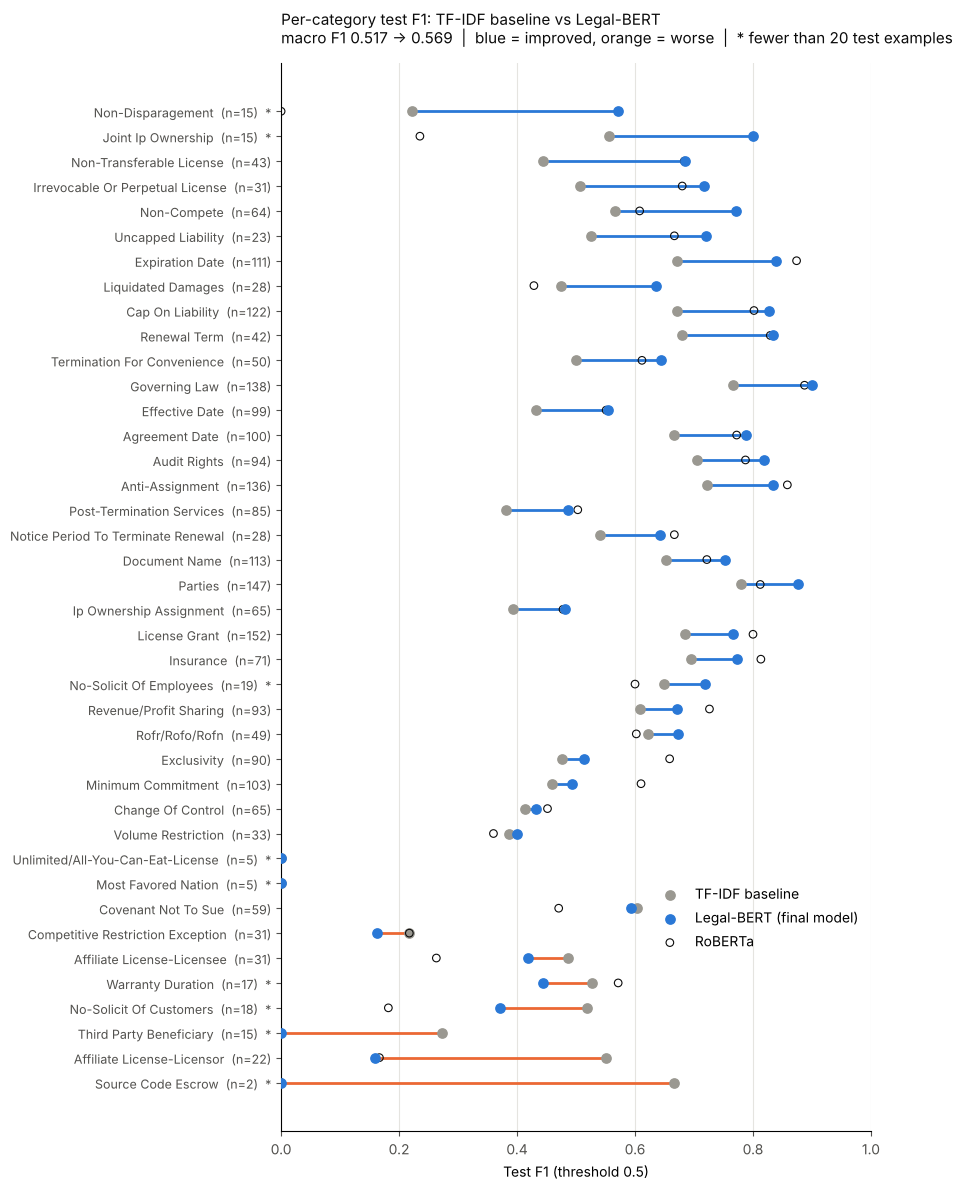

In [9]:
plot_df = table.dropna(subset=['legalbert_f1']).sort_values('legalbert_change')
GREY, BLUE, ORANGE, INK, MUTED = '#9a9891', '#2a78d6', '#eb6834', '#0b0b0b', '#52514e'

fig, ax = plt.subplots(figsize=(9, 12))
y = np.arange(len(plot_df))
for yi, (cat, row) in zip(y, plot_df.iterrows()):
    color = BLUE if row['legalbert_change'] >= 0 else ORANGE
    ax.plot([row['tfidf_f1'], row['legalbert_f1']], [yi, yi], color=color, linewidth=2, zorder=1)
ax.scatter(plot_df['tfidf_f1'], y, color=GREY, s=45, zorder=2, label='TF-IDF baseline')
ax.scatter(plot_df['legalbert_f1'], y, color=BLUE, s=45, zorder=3, label='Legal-BERT (final model)')
ax.scatter(plot_df['roberta_f1'], y, facecolors='none', edgecolors=INK, s=30, linewidths=0.8, zorder=2, label='RoBERTa')

labels = [f"{c}  (n={int(r['test_support'])})" + ('  *' if r['few_test_examples'] else '') for c, r in plot_df.iterrows()]
ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=9)
ax.set_xlim(0, 1)
ax.set_xlabel('Test F1 (threshold 0.5)')
macro_tfidf = overall.loc[('TF-IDF', 'macro'), 'f1']
macro_lb = overall.loc[('Legal-BERT', 'macro'), 'f1']
ax.set_title(f"Per-category test F1: TF-IDF baseline vs Legal-BERT\nmacro F1 {macro_tfidf:.3f} -> {macro_lb:.3f}  |  blue = improved, orange = worse  |  * fewer than 20 test examples",
             loc='left', color=INK, fontsize=11, pad=14)
ax.legend(loc='center right', bbox_to_anchor=(1.0, 0.2), frameon=False)   # empty space beside the two F1 = 0 rows
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.tick_params(colors=MUTED)
ax.grid(axis='x', color='#e5e4e0', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/baseline_vs_transformer_f1.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Why did it change? Precision vs. recall

F1 alone hides *how* a model wins or loses. The baseline used `class_weight='balanced'`, which pushes it to say "yes" more often: high recall, low precision (many false alarms). The transformers were trained with no class weights and a fixed 0.5 threshold, so they are the opposite: high precision, lower recall (they miss clauses, especially rare ones). This matters for the Task #3 threshold tuning and for the risk-scoring layer in November, where a missed clause costs more than a false alarm.

In [10]:
pr_table = pd.DataFrame({
    'test_support': scores['TF-IDF']['test_support'],
    'tfidf_precision': scores['TF-IDF']['precision'], 'tfidf_recall': scores['TF-IDF']['recall'],
    'legalbert_precision': scores['Legal-BERT']['precision'], 'legalbert_recall': scores['Legal-BERT']['recall'],
}, index=CATEGORIES)
pr_table['precision_change'] = pr_table['legalbert_precision'] - pr_table['tfidf_precision']
pr_table['recall_change'] = pr_table['legalbert_recall'] - pr_table['tfidf_recall']
pr_table.index.name = 'category'
pr_table.to_csv(f'{OUT_DIR}/baseline_vs_legalbert_precision_recall.csv')

m = pr_table[measurable]
print(f"Categories where Legal-BERT has higher precision than TF-IDF: {(m['precision_change'] > 0).sum()} of 40")
print(f"Categories where Legal-BERT has higher recall than TF-IDF:    {(m['recall_change'] > 0).sum()} of 40")
print(f"Legal-BERT predicts 'yes' on {int(((probs['Legal-BERT'] >= THRESHOLD)).sum()):,} chunk-category pairs vs "
      f"{int((tfidf_probs >= THRESHOLD).sum()):,} for TF-IDF (true positives in test: {int(y_test.sum()):,})")
print("\nCategories where Legal-BERT never predicts 'yes' on test (recall 0):")
print(list(m.index[(m['legalbert_recall'] == 0)]))
print("\nLargest recall drops (where the transformer now misses clauses the baseline caught):")
print(m.sort_values('recall_change')[['test_support', 'tfidf_recall', 'legalbert_recall', 'recall_change', 'tfidf_precision', 'legalbert_precision']].head(8).round(3))

Categories where Legal-BERT has higher precision than TF-IDF: 33 of 40
Categories where Legal-BERT has higher recall than TF-IDF:    10 of 40
Legal-BERT predicts 'yes' on 2,017 chunk-category pairs vs 3,208 for TF-IDF (true positives in test: 2,429)

Categories where Legal-BERT never predicts 'yes' on test (recall 0):
['Most Favored Nation', 'Source Code Escrow', 'Third Party Beneficiary', 'Unlimited/All-You-Can-Eat-License']

Largest recall drops (where the transformer now misses clauses the baseline caught):
                             test_support  tfidf_recall  legalbert_recall  recall_change  tfidf_precision  legalbert_precision
category                                                                                                                      
Source Code Escrow                      2         0.500             0.000         -0.500            1.000                0.000
Affiliate License-Licensor             22         0.500             0.091         -0.409            0.6

## 8. Rare categories

`Labeling.ipynb` and Task #5 focus on the 13 rare categories (under 1% of chunks). Here are the ones with fewer than 100 training positives (the baseline notebook's definition of rare), with all three models.

In [11]:
rare = table[table['train_support'] < 100].sort_values('train_support')
rare[['train_support', 'test_support', 'tfidf_f1', 'roberta_f1', 'legalbert_f1', 'legalbert_change', 'result']].round(3)

,train_support,test_support,tfidf_f1,roberta_f1,legalbert_f1,legalbert_change,result
category,,,,,,,
Unlimited/All-You-Can-Eat-License,31,5,0.000,0.000,0.000,0.000,about the same
Price Restrictions,34,0,NaN,NaN,NaN,NaN,not measurable
Third Party Beneficiary,42,15,0.273,0.000,0.000,-0.273,got worse
Source Code Escrow,47,2,0.667,0.000,0.000,-0.667,got worse
Most Favored Nation,51,5,0.000,0.000,0.000,0.000,about the same
No-Solicit Of Customers,53,18,0.519,0.182,0.370,-0.148,got worse
Affiliate License-Licensor,63,22,0.550,0.167,0.160,-0.390,got worse
Non-Disparagement,64,15,0.222,0.000,0.571,0.349,improved
No-Solicit Of Employees,86,19,0.649,0.600,0.718,0.069,improved


## 9. Summary (for the README)

**Headline.** Fine-tuning a transformer beats the TF-IDF baseline. On the 2,898 test chunks (40 measurable categories, threshold 0.5), **Legal-BERT reaches micro F1 0.703 and macro F1 0.569, vs 0.591 and 0.517 for the baseline** (+0.11 micro, +0.05 macro). RoBERTa is in between (0.692 / 0.524). Per category, **Legal-BERT improves on the baseline in 28 of 40 categories, is about the same in 5, and is worse in 7.** It beats RoBERTa in 23 of 40, which supports Task #2's choice of Legal-BERT as the final model.

**Where the transformer helps most.**
- **Clauses whose meaning depends on context rather than a few key words:** Non-Disparagement (0.22 -> 0.57), Joint IP Ownership (0.56 -> 0.80), Non-Transferable License (0.44 -> 0.68), Irrevocable Or Perpetual License (0.51 -> 0.72), Non-Compete (0.57 -> 0.77), Uncapped Liability (0.53 -> 0.72), Liquidated Damages (0.47 -> 0.64). The baseline confused these with neighbouring clause types (e.g. Non-Transferable License vs. License Grant); the transformer reads the whole sentence.
- **The core "always present" clauses get very reliable:** Governing Law 0.90, Parties 0.88, Expiration Date 0.84, Anti-Assignment 0.83, Renewal Term 0.83, Cap On Liability 0.83, Audit Rights 0.82. Eight categories now have F1 >= 0.8; the baseline had none.

**Where it is still weak.** The baseline's "false alarm" group (Post-Termination Services, IP Ownership Assignment, Change Of Control, Minimum Commitment, Exclusivity, Effective Date, Volume Restriction) does improve, but only to F1 0.40 to 0.55. These clauses share vocabulary with other clauses (*termination*, *exclusive*, *date*) and remain the hardest common categories. Interestingly, RoBERTa does better than Legal-BERT on Exclusivity (0.66 vs 0.51) and Minimum Commitment (0.61 vs 0.49), so the two models have different strengths. The number of weak categories (F1 < 0.5) only drops from 15 to 14.

**Where it got worse: rare categories.** All 7 categories that got worse have fewer than 125 training examples and most have fewer than 20 test examples: Source Code Escrow (0.67 -> 0.00, but only 2 test chunks), Affiliate License-Licensor (0.55 -> 0.16), Third Party Beneficiary (0.27 -> 0.00), No-Solicit Of Customers (0.52 -> 0.37), Warranty Duration, Affiliate License-Licensee, Competitive Restriction Exception. Four categories are never predicted at all on test (recall 0): Most Favored Nation, Unlimited/All-You-Can-Eat-License, Third Party Beneficiary, Source Code Escrow. Price Restrictions has no test positives and cannot be measured.

**Why: the precision / recall trade-off.** Legal-BERT has higher precision than the baseline in 33 of 40 categories but higher recall in only 10. It flags 2,017 chunk-category pairs in test vs 3,208 for the baseline (there are 2,429 true ones), so it under-predicts. The baseline's `class_weight='balanced'` forced it to say "yes" more often; the transformer was trained with no class weights and a fixed 0.5 threshold, so for rare clauses its probabilities rarely reach 0.5. For contract risk review, a missed clause costs more than a false alarm, so recall matters more. **This makes Task #3 (per-category thresholds, `pos_weight`, oversampling) the most important next step**: lowering the threshold for rare categories should recover much of the lost recall without giving back the precision gains.

**Caveats.** Chunk-level scores, not contract-level. One training run and one seed per model (about ±0.01 noise, so differences under 0.02 are treated as "about the same"). The baseline trained on all 408 training contracts, the transformers on 347 (61 held out for validation), which slightly favors the baseline. Categories with fewer than 20 test chunks (marked `*` in the chart) have very noisy scores. The test set was used once, for this comparison only.

**Files saved to `results/comparison/`:** `baseline_vs_transformer_per_category.csv` (the table), `baseline_vs_legalbert_precision_recall.csv`, `baseline_vs_transformer_f1.png` (the chart).